In [1]:
## Python Stuff
import os
import sys
import numpy as np
from array import array
import copy
import time
import matplotlib.pyplot as plt

In [2]:
#1. load in the data and mac into FullMCRun object
#2. make the histograms (done)

## real data ##
#1. load in the data using my old code
#2. when do I change it to new 'format' with uproot?

#3. proceed outside of a root architechture

In [3]:
## ROOT stuff
import uproot
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(500)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
# ROOT.enableJSVis()
# ROOT.disableJSVis()

Welcome to JupyROOT 6.27/01


In [4]:
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")
sys.path.append(os.environ.get("CF4G4")+"/Batch/")
print(sys.path)

# for MC data getting
# import helpers.FileGetters as FG

from helpers.G4_runClasses import *
from helpers.G4_macHelpers import *

['/Users/austindestcroix', '/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311/lib', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python311.zip', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/lib-dynload', '', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/']


In [5]:
# Opening files
pathToFiles = os.environ.get("CF4G4")+"/Batch/may5_2023-manualTesting_gammaHeights/"
print(pathToFiles)
fname = "Cs137_-0d5cm"

mcRun = FullMCRun(macName = pathToFiles+fname)

# print(fullF1.mPhysPars.ly)

fInDir = os.listdir(pathToFiles)
# fList = [f for f in fInDir if f.endswith('.root')]
# macList = [f for f in fInDir if f.endswith('.mac')]

/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/may5_2023-manualTesting_gammaHeights/
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/may5_2023-manualTesting_gammaHeights/Cs137_-0d5cm.root


8063


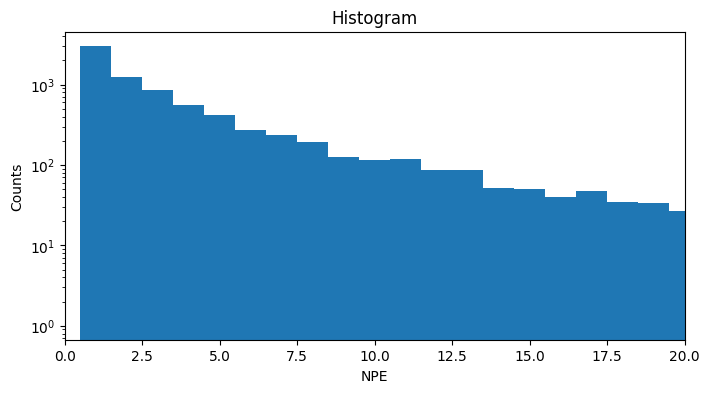

In [10]:
c = TCanvas()

fNPE = mcRun.mTtree["fNPE"].array()
fNPE = fNPE[fNPE > 0]
print(len(fNPE))

plt.figure(1, figsize=(8, 4))
plt.hist(fNPE, bins=100, range=(0.5, 100.5))

plt.xlim(0, 20)
plt.xlabel("NPE")
plt.ylabel("Counts")
plt.title("Histogram")
plt.yscale("log")
plt.show()

In [110]:
mcRun.setup_forComparison(100, 0.5, 200.5)

sampleNPE = mcRun.mNPE

print(len(sampleNPE))
print(sampleNPE)

smallNPE = sampleNPE[3:8]

8063
[34, 5, 2, 3, 1, 15, 4, 1, 5, 1, 59, 5, ..., 4, 3, 7, 1, 1, 20, 16, 2, 1, 6, 6]


In [112]:
## doing for DN to show that geometric is the correct approach
sampleDN = np.ones(10000, dtype=int)
pGeo = 1./1.17 # 0.16 is NCA from Giacomo/nEXO paper
print("pGeo = ", pGeo)

PE_DN = [np.sum(np.random.default_rng().geometric(p = pGeo, size = pe)) for pe in sampleDN]
np.mean(PE_DN)

pGeo =  0.8547008547008548


1.1723

In [120]:
## testing noise code ##

import time
startTime = time.time()

test = []
mynpRand = np.random.default_rng(seed = int(time.time()))

for i in range(100):
  test = [np.sum(mynpRand.geometric(p = pGeo, size = pe)) for pe in sampleNPE]

endTime = time.time()
elapsed = endTime - startTime

print(np.mean(sampleNPE))
np.mean(test)
print("geometric time: ", elapsed)

6.163338707677044
geometric time:  2.711236000061035


In [118]:

x = []

# numpy
startTime = time.time()

for i in range(100):
  x = np.random.binomial(sampleNPE, 0.50)

endTime = time.time()
elapsed = endTime - startTime

print(elapsed, np.sum(x), len(x))

# pyroot
rand = ROOT.TRandom3()
startTime = time.time()

for i in range(100):
  x = [rand.Binomial(int(pe), 0.5) for pe in sampleNPE]

endTime = time.time()
elapsed = endTime - startTime

print(elapsed, np.sum(x), len(x))


0.0859079360961914 24974 8063
0.41567397117614746 24862 8063


1